# Lab 2 — Music Genre Classification with CNNs

This notebook implements both tasks in the lab guide: (1) compare simple CNN configurations using the provided mel-spectrogram images, and (2) fine-tune a pretrained VGG16 model. Both tasks use the same shuffled, stratified 80/20 train/test split. The test set is held out until final evaluation.

## 1. Setup and reproducibility

The notebook is designed for Google Colab or Jupyter. A GPU is recommended, especially for VGG16.

In [7]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 2. Load the spectrogram dataset

Download the files linked in the lab handout. Extract the `images_original` directory so that it contains one subdirectory per genre (for example, `images_original/blues/`). Set `DATA_DIR` below to that directory. Do not use the CSV global descriptors for these CNN experiments; the task specifically asks for the provided spectrogram images.

In [8]:
# Download and extract the provided images_original folder first.
# Change this path if your images are stored elsewhere.
DATA_DIR = Path("data/images_original")

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR.resolve()}")

# Each subfolder is a genre; each image is one example.
images = [
    {"path": str(image), "genre": folder.name}
    for folder in sorted(DATA_DIR.iterdir()) if folder.is_dir()
    for image in sorted(folder.iterdir())
    if image.suffix.lower() in {".png", ".jpg", ".jpeg"}
]
df = pd.DataFrame(images)
if df.empty:
    raise ValueError("No spectrogram images found.")

print(f"{len(df)} images, {df['genre'].nunique()} genres")
display(df.groupby("genre").size().rename("images"))


999 images, 10 genres


genre
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz          99
metal        100
pop          100
reggae       100
rock         100
Name: images, dtype: int64

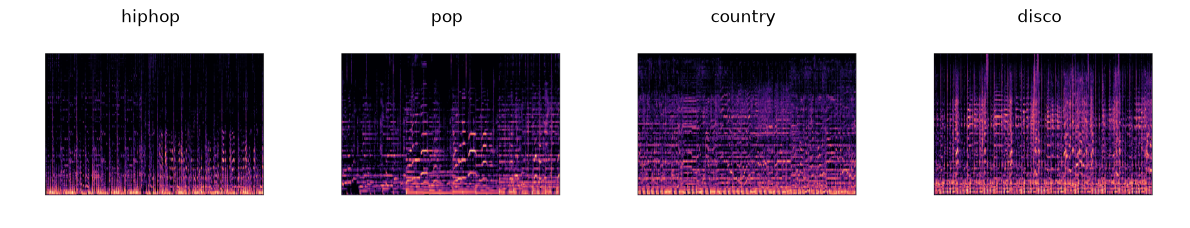

In [9]:
# Display a few spectrograms.
sample = df.sample(min(4, len(df)), random_state=SEED)
fig, axes = plt.subplots(1, len(sample), figsize=(12, 3))
for ax, (_, row) in zip(np.atleast_1d(axes), sample.iterrows()):
    ax.imshow(plt.imread(row["path"]))
    ax.set_title(row["genre"])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Shared shuffled 80/20 train/test split

The split is stratified to preserve genre proportions. The 20% test set is identical for both model families. Model selection uses only a validation subset of the 80% training partition.

In [10]:
# 80% for model development, 20% held out for final testing.
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["genre"], random_state=SEED
)

# Validation comes ONLY from the training portion.
train_df, val_df = train_test_split(
    train_df, test_size=0.2, stratify=train_df["genre"], random_state=SEED
)

class_names = sorted(df["genre"].unique())
class_to_id = {genre: i for i, genre in enumerate(class_names)}
num_classes = len(class_names)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")


Train: 639 | Validation: 160 | Test: 200


## 4. Task 1 — train and compare simple CNNs

All configurations use the same training/validation split and input size. The small grid varies the number of convolutional blocks and filters. Early stopping selects the best epoch using validation loss; the test set is not used to choose the architecture.

In [ ]:
# One data-loading function works for both the simple CNN and VGG16.def make_dataset(data, size, batch_size=32, vgg=False, shuffle=False):    paths = data["path"].to_numpy()    labels = data["genre"].map(class_to_id).to_numpy()    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))    def load_image(path, label):        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)        image.set_shape((None, None, 3))        image = tf.image.resize(image, (size, size))        if vgg:            # VGG16 expects pixel values in the original 0–255 range.            image = tf.keras.applications.vgg16.preprocess_input(image)        else:            image = image / 255.0        return image, label    dataset = dataset.map(load_image)    if shuffle:        dataset = dataset.shuffle(len(data), seed=SEED)    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)train_ds = make_dataset(train_df, 128, shuffle=True)val_ds = make_dataset(val_df, 128)test_ds = make_dataset(test_df, 128)def build_cnn(filters):    model = tf.keras.Sequential([        tf.keras.layers.Input(shape=(128, 128, 3)),        *[            layer            for n_filters in filters            for layer in (                tf.keras.layers.Conv2D(n_filters, kernel_size=3, activation="relu", padding="same"),                tf.keras.layers.MaxPool2D(pool_size=2, strides=2),            )        ],        tf.keras.layers.GlobalAveragePooling2D(),        tf.keras.layers.Dense(64, activation="relu"),        tf.keras.layers.Dense(num_classes, activation="softmax"),    ])    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])    return modeldef generate_model():    """CNN architecture based on the reference model provided for the lab."""    model = tf.keras.Sequential([        tf.keras.layers.Input(shape=(128, 128, 3)),        tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu"),        tf.keras.layers.MaxPool2D(pool_size=2, strides=2),        tf.keras.layers.Conv2D(64, kernel_size=3, activation="relu"),        tf.keras.layers.MaxPool2D(pool_size=2, strides=2),        tf.keras.layers.Flatten(),        tf.keras.layers.Dense(1024, activation="relu"),        tf.keras.layers.Dense(num_classes, activation="softmax"),    ])    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])    return model# Compare the existing CNN configurations with the reference architecture.configurations = [(32, 64), (32, 128), (32, 64, 128)]cnn_models = {}cnn_results = []def train_and_record_cnn(name, model, description):    model.fit(        train_ds,        validation_data=val_ds,        epochs=20,        verbose=1,        shuffle=False,  # train_ds is already shuffled        callbacks=[tf.keras.callbacks.EarlyStopping(            monitor="val_loss", patience=4, restore_best_weights=True        )],    )    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)    cnn_models[name] = model    cnn_results.append({        "model": name,        "configuration": description,        "validation_accuracy": val_accuracy,        "validation_loss": val_loss,    })for filters in configurations:    name = f"CNN_{'_'.join(map(str, filters))}"    print(f"Training {name}")    train_and_record_cnn(name, build_cnn(filters), str(filters))print("Training the reference CNN")train_and_record_cnn("CNN_reference", generate_model(), "Conv32-Conv64-Flatten-Dense1024")cnn_results_df = pd.DataFrame(cnn_results).sort_values("validation_accuracy", ascending=False)display(cnn_results_df)

In [ ]:
# Choose the CNN using validation accuracy, never test accuracy.
best_cnn_name = cnn_results_df.iloc[0]["model"]
best_cnn = cnn_models[best_cnn_name]


def evaluate_model(model, dataset, name):
    loss, accuracy = model.evaluate(dataset, verbose=0)
    true_labels = np.concatenate([labels.numpy() for _, labels in dataset])
    predictions = model.predict(dataset, verbose=0).argmax(axis=1)

    print(f"\n{name} — test accuracy: {accuracy:.4f}")
    print(classification_report(
        true_labels, predictions, labels=range(num_classes),
        target_names=class_names, zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        true_labels, predictions, display_labels=class_names,
        xticks_rotation=45, cmap="Blues"
    )
    plt.title(f"{name} — test confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": name, "test_accuracy": accuracy, "test_loss": loss}


final_results = [evaluate_model(best_cnn, test_ds, best_cnn_name)]


## 5. Task 2 — fine-tune a pretrained model (VGG16)

The lab gives VGGish as an example of a pretrained model. Here we use ImageNet-pretrained VGG16, a widely available deep CNN, as a transfer-learning baseline for the provided RGB spectrogram images. The convolutional backbone is initially frozen while a new genre classifier is trained; then the final convolutional block is unfrozen and fine-tuned at a low learning rate. This is a spectrogram-image transfer-learning experiment, not the audio-waveform VGGish model.

In [ ]:
# Use the SAME train/validation/test image split as for the CNN.
vgg_train = make_dataset(train_df, 224, batch_size=16, vgg=True, shuffle=True)
vgg_val = make_dataset(val_df, 224, batch_size=16, vgg=True)
vgg_test = make_dataset(test_df, 224, batch_size=16, vgg=True)

# Load VGG16 pretrained on ImageNet, without its original classifier.
base = tf.keras.applications.VGG16(
    weights="imagenet", include_top=False, input_shape=(224, 224, 3)
)
base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
vgg_model = tf.keras.Model(inputs, outputs)

# First, train only the new genre classifier.
vgg_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
vgg_model.fit(vgg_train, validation_data=vgg_val, epochs=5)

# Then fine-tune the last VGG16 convolutional block.
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("block5_")

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
vgg_model.fit(
    vgg_train, validation_data=vgg_val, epochs=8,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )]
)

final_results.append(evaluate_model(vgg_model, vgg_test, "VGG16_finetuned"))


In [ ]:
# Compare the selected CNN and fine-tuned pretrained model on the same held-out test partition.
results_df = pd.DataFrame(final_results).sort_values('test_accuracy', ascending=False)
display(results_df)
results_df.to_csv('lab2_test_results.csv', index=False)
cnn_results_df.to_csv('lab2_cnn_configuration_results.csv', index=False)
print('Saved lab2_test_results.csv and lab2_cnn_configuration_results.csv')

## 6. Discussion and Lab 1 comparison

Use the measured results above to complete the discussion; do not assume a result in advance.

- Report the validation scores for every CNN configuration and explain the selection criterion.
- Report test accuracy, loss, classification report and confusion matrix for the selected CNN and VGG16.
- Discuss which genres are most frequently confused, using the confusion matrices as evidence.
- Compare these results with the manually extracted-feature models from Lab 1. Include the actual Lab 1 scores, the split/evaluation protocol, computational cost and any differences in overfitting. The Lab 1 CSV features and the spectrogram CNNs represent different input representations, so state this when interpreting the comparison.
- Because the test set is held out from architecture selection, use test performance only for final reporting, not further tuning.

## 7. Reproducibility notes

- Keep `SEED = 42` unchanged to reproduce the same split.
- The first run of VGG16 downloads pretrained ImageNet weights; internet access is required for that download.
- Results can vary slightly with TensorFlow version, hardware, and nondeterministic GPU operations.
- The lab dataset contains original spectrogram images; verify folder names and image counts before training.
- The notebook does not modify or depend on files inside `Lab1/`.